## Indian Banking Fraud Detection

In [3]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

In [4]:
DATA_PATH = Path("../data/raw/indian_banking_transactions.csv")

df = pd.read_csv(DATA_PATH)


## Data Information

In [5]:
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
0,TXN000000001,CUST015796,2019-01-01,15:28,Current,UPI,1820.17,Debit,609365.31,Food & Dining,Maharashtra,764,0,NaN,0.00,Success,Branch,Verified,0,15
1,TXN000000002,CUST000861,2019-01-01,03:00,Current,UPI,392.67,Credit,14451.14,Education,West Bengal,630,0,NaN,0.00,Success,Mobile_App,Verified,0,3
2,TXN000000003,CUST076821,2019-01-01,18:03,Fixed Deposit,POS,1255.97,Debit,47621.87,Utilities,Punjab,813,1,Home,1433.91,Success,Mobile_App,Verified,0,18
3,TXN000000004,CUST054887,2019-01-01,08:03,Savings,UPI,2580.68,Debit,34467.85,Travel,Karnataka,628,1,Personal,6280.35,Success,API,Verified,0,8
4,TXN000000005,CUST006266,2019-01-01,14:23,Fixed Deposit,UPI,2573.80,Debit,26617.40,Utilities,West Bengal,767,0,NaN,0.00,Success,API,Verified,0,14


In [6]:
print("Shape:", df.shape)

df.sample(5)

Shape: (550000, 20)


,transaction_id,customer_id,transaction_date,transaction_time,account_type,transaction_type,transaction_amount,transaction_direction,account_balance,merchant_category,state,credit_score,has_loan,loan_type,emi_amount,transaction_status,channel,kyc_status,is_fraud,transaction_hour
510686,TXN000510687,CUST051871,2023-08-23,11:22,Current,UPI,4517.35,Credit,16113.47,Education,Tamil Nadu,827,0,NaN,0.00,Success,API,Verified,0,11
36536,TXN000036537,CUST013990,2019-05-03,10:13,Savings,UPI,812.38,Debit,7752.08,Entertainment,Punjab,483,0,NaN,0.00,Success,Web,Pending,0,10
96244,TXN000096245,CUST031841,2019-11-15,20:58,Savings,UPI,1449.65,Debit,11111.78,Peer Transfer,Telangana,340,1,Business,4448.15,Success,POS_Terminal,Verified,0,20
236808,TXN000236809,CUST006172,2021-02-25,07:42,Current,UPI,5016.62,Debit,14501.21,Food & Dining,Delhi,844,0,NaN,0.00,Success,Mobile_App,Verified,0,7
173258,TXN000173259,CUST075533,2020-07-29,09:04,Salary,NEFT,1124.94,Debit,79677.73,Food & Dining,Telangana,797,1,Business,15216.76,Success,Branch,Verified,0,9


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         550000 non-null  str    
 1   customer_id            550000 non-null  str    
 2   transaction_date       550000 non-null  str    
 3   transaction_time       550000 non-null  str    
 4   account_type           550000 non-null  str    
 5   transaction_type       550000 non-null  str    
 6   transaction_amount     550000 non-null  float64
 7   transaction_direction  550000 non-null  str    
 8   account_balance        550000 non-null  float64
 9   merchant_category      550000 non-null  str    
 10  state                  550000 non-null  str    
 11  credit_score           550000 non-null  int64  
 12  has_loan               550000 non-null  int64  
 13  loan_type              172866 non-null  str    
 14  emi_amount             550000 non-null  float64

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,550000,550000,TXN000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,550000,79916,CUST003688,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,550000,1827,2023-11-11,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_time,550000,1440,06:25,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_type,550000,5,Savings,219651,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_type,550000,10,UPI,153986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_amount,550000.0,NaN,NaN,NaN,29907.093934,139610.09652,2.4,763.0375,2035.735,8557.4975,10000000.0
transaction_direction,550000,2,Debit,370394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_balance,550000.0,NaN,NaN,NaN,84550.115076,170914.586239,500.0,15157.785,36422.87,87607.035,5000000.0
merchant_category,550000,15,Retail,66180,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Missing Values

In [9]:
df.isnull().sum()

(df.isnull().sum()/len(df))*100

transaction_id            0.000000
customer_id               0.000000
transaction_date          0.000000
transaction_time          0.000000
account_type              0.000000
transaction_type          0.000000
transaction_amount        0.000000
transaction_direction     0.000000
account_balance           0.000000
merchant_category         0.000000
state                     0.000000
credit_score              0.000000
has_loan                  0.000000
loan_type                68.569818
emi_amount                0.000000
transaction_status        0.000000
channel                   0.000000
kyc_status                0.000000
is_fraud                  0.000000
transaction_hour          0.000000
dtype: float64

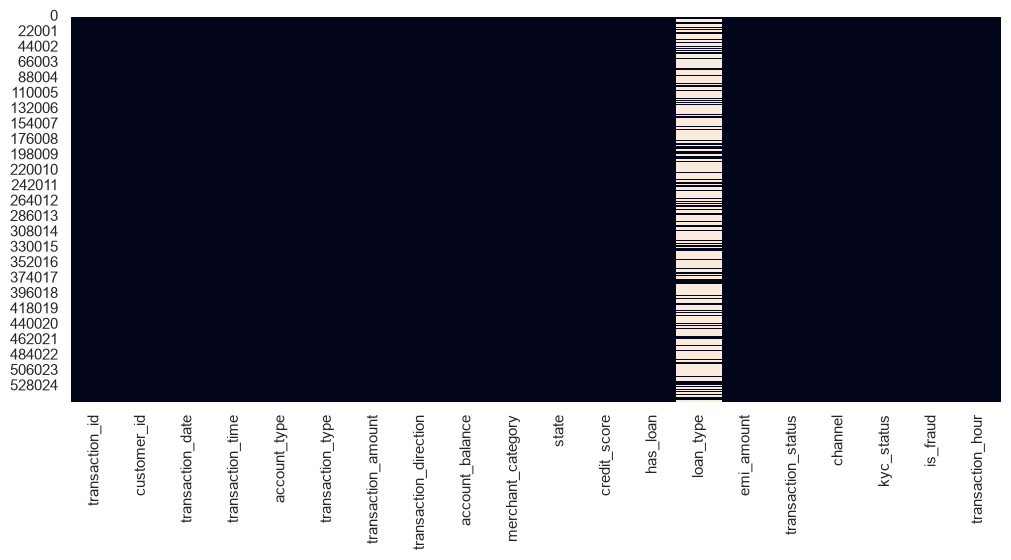

In [10]:
plt.figure(figsize=(12,5))
sns.heatmap(df.isnull(), cbar=False)
plt.show()

## Duplicate Records

In [11]:
duplicates = df.duplicated().sum()

print(f"Duplicate Rows : {duplicates}")

Duplicate Rows : 0


## Unique Values

In [12]:
df.nunique().sort_values()

transaction_direction         2
has_loan                      2
is_fraud                      2
kyc_status                    3
transaction_status            4
account_type                  5
loan_type                     6
channel                       6
transaction_type             10
state                        10
merchant_category            15
transaction_hour             24
credit_score                600
transaction_time           1440
transaction_date           1827
customer_id               79916
emi_amount               177524
transaction_amount       374552
account_balance          536170
transaction_id           550000
dtype: int64

## Data Validation

In [13]:
df["transaction_id"].is_unique

True

In [14]:
df["customer_id"].nunique()

79916

## Target Distribution

In [15]:
df["is_fraud"].value_counts()
df["is_fraud"].value_counts(normalize=True)*100

is_fraud
0    99.114
1     0.886
Name: proportion, dtype: float64

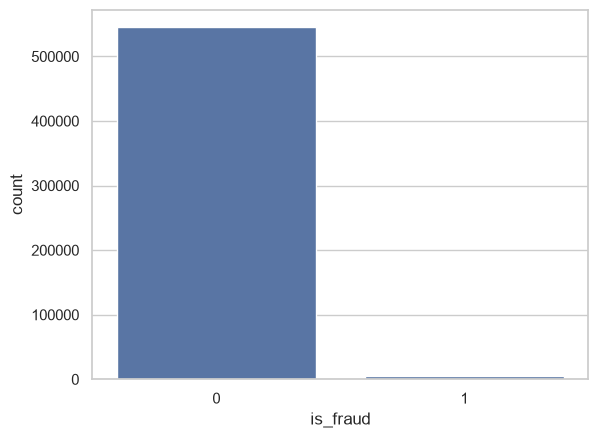

In [16]:
sns.countplot(data=df,x="is_fraud")
plt.show()

## Separate Features

In [17]:
num_cols = df.select_dtypes(include=np.number).columns

cat_cols = df.select_dtypes(include="object").columns

print(num_cols)

print(cat_cols)

Index(['transaction_amount', 'account_balance', 'credit_score', 'has_loan',
       'emi_amount', 'is_fraud', 'transaction_hour'],
      dtype='str')
Index(['transaction_id', 'customer_id', 'transaction_date', 'transaction_time',
       'account_type', 'transaction_type', 'transaction_direction',
       'merchant_category', 'state', 'loan_type', 'transaction_status',
       'channel', 'kyc_status'],
      dtype='str')


## Numerical Analysis

In [18]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_amount,550000.0,29907.093934,139610.096520,2.4,763.0375,2035.735,8557.4975,10000000.00
account_balance,550000.0,84550.115076,170914.586239,500.0,15157.7850,36422.870,87607.0350,5000000.00
credit_score,550000.0,599.807009,173.054597,300.0,450.0000,600.000,750.0000,899.00
has_loan,550000.0,0.349615,0.476849,0.0,0.0000,0.000,1.0000,1.00
emi_amount,550000.0,2365.859974,4973.546080,0.0,0.0000,0.000,3115.0300,153325.74
is_fraud,550000.0,0.008860,0.093710,0.0,0.0000,0.000,0.0000,1.00
transaction_hour,550000.0,11.504431,6.924499,0.0,6.0000,11.000,17.0000,23.00


## Histograms

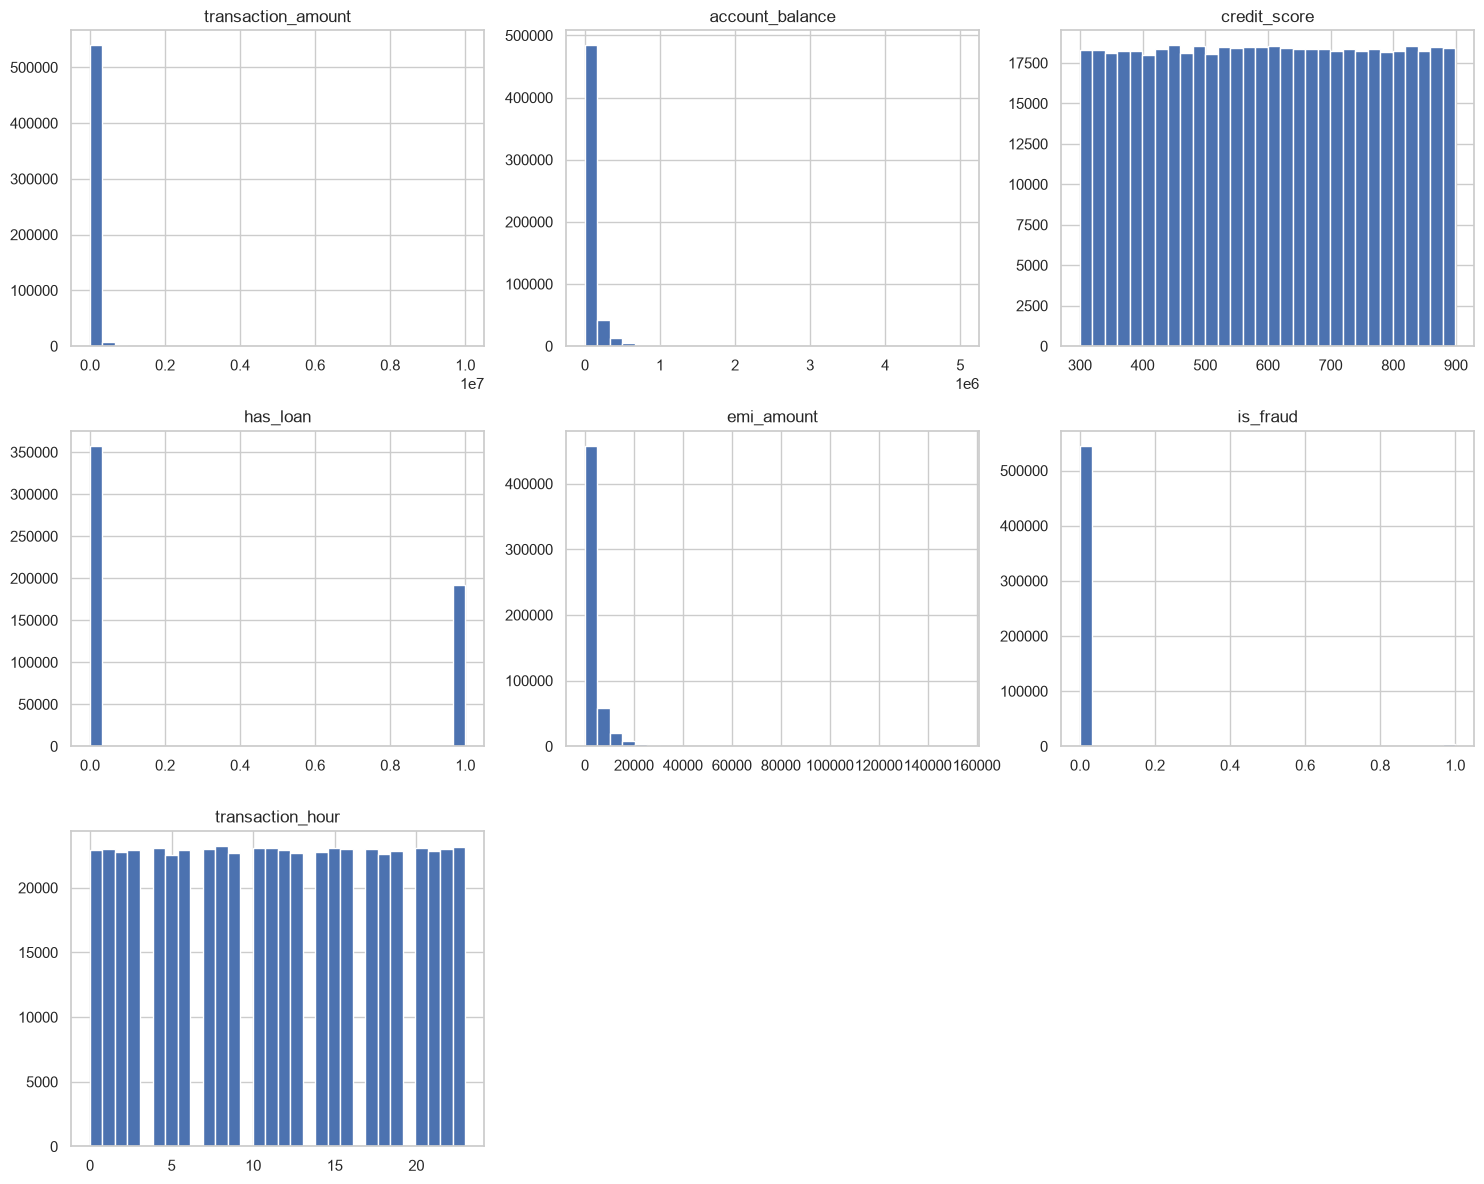

In [19]:
df[num_cols].hist(
    figsize=(15,12),
    bins=30
)

plt.tight_layout()

## Boxplots

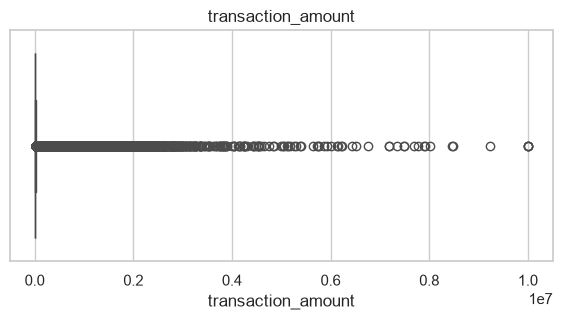

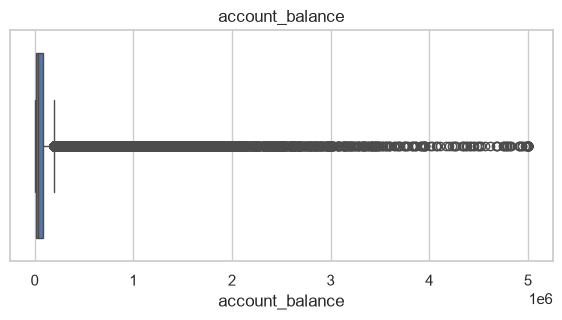

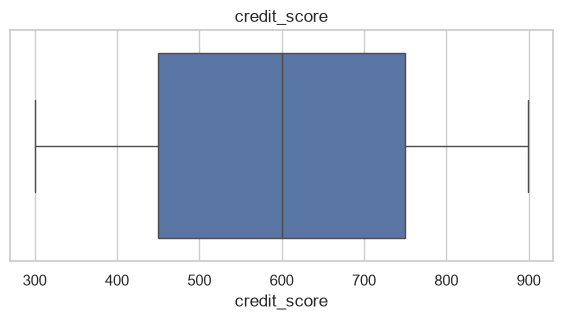

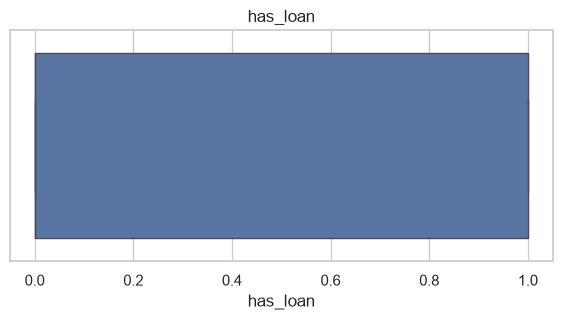

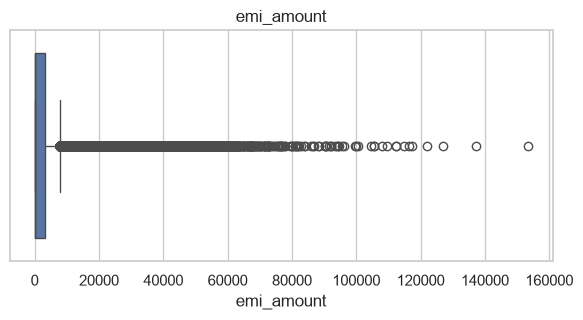

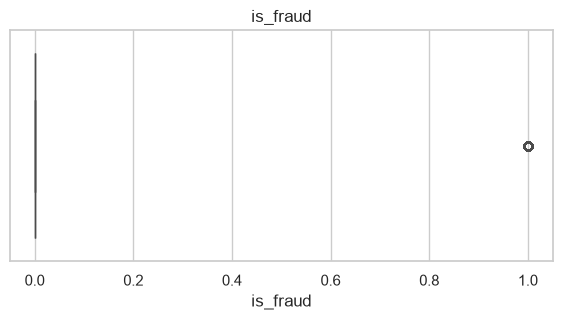

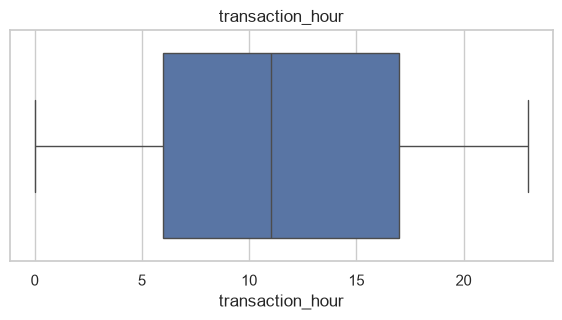

In [20]:
for col in num_cols:

    plt.figure(figsize=(7,3))

    sns.boxplot(x=df[col])

    plt.title(col)

    plt.show()

## Outlier Detection

In [21]:
Q1=df[num_cols].quantile(.25)

Q3=df[num_cols].quantile(.75)

IQR=Q3-Q1

outliers=((df[num_cols]<(Q1-1.5*IQR))|
          (df[num_cols]>(Q3+1.5*IQR))).sum()

outliers

transaction_amount    88976
account_balance       53567
credit_score              0
has_loan                  0
emi_amount            54281
is_fraud               4873
transaction_hour          0
dtype: int64

## Skewness

In [22]:
df[num_cols].skew()

transaction_amount    18.813860
account_balance        9.320360
credit_score          -0.001503
has_loan               0.630749
emi_amount             4.341817
is_fraud              10.482192
transaction_hour       0.000283
dtype: float64

## Categorical Analysis

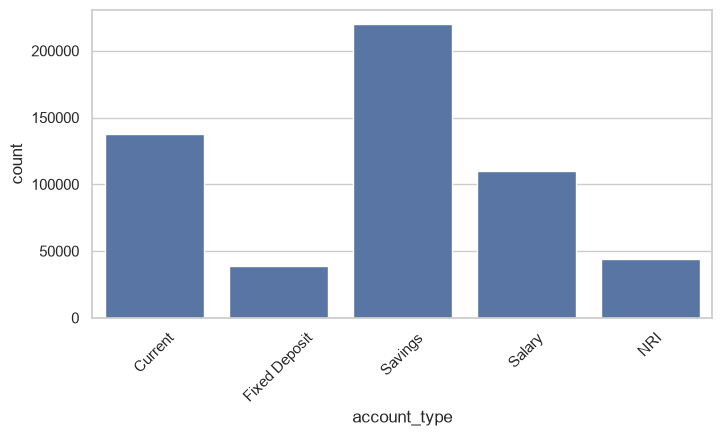

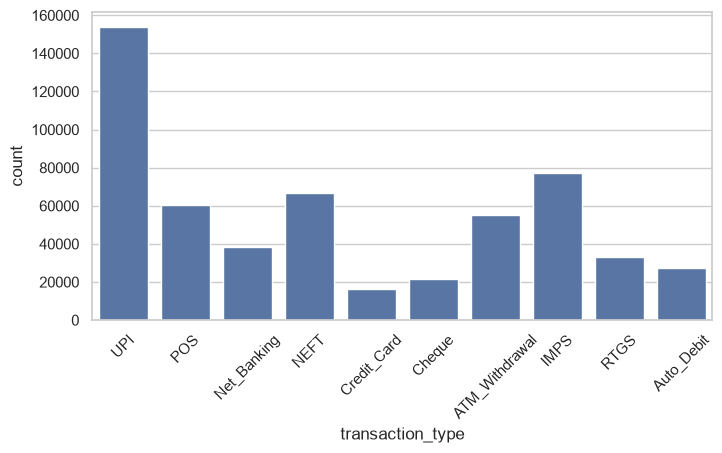

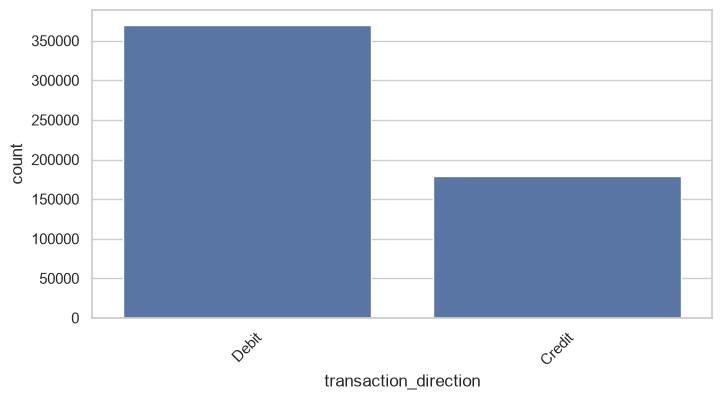

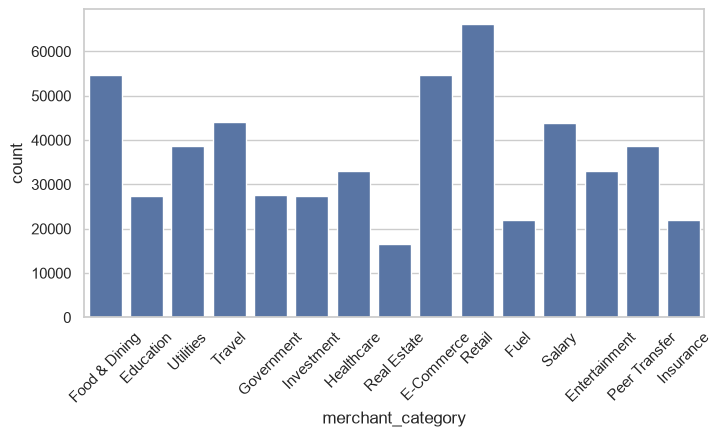

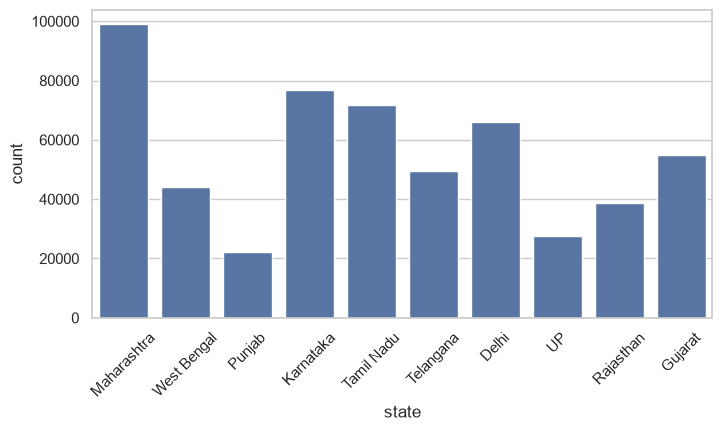

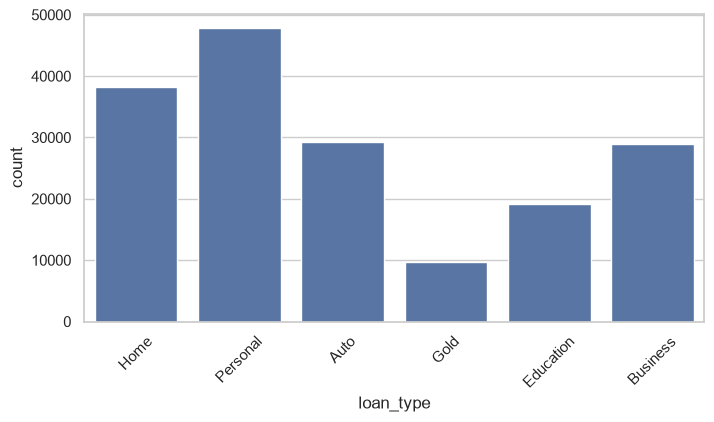

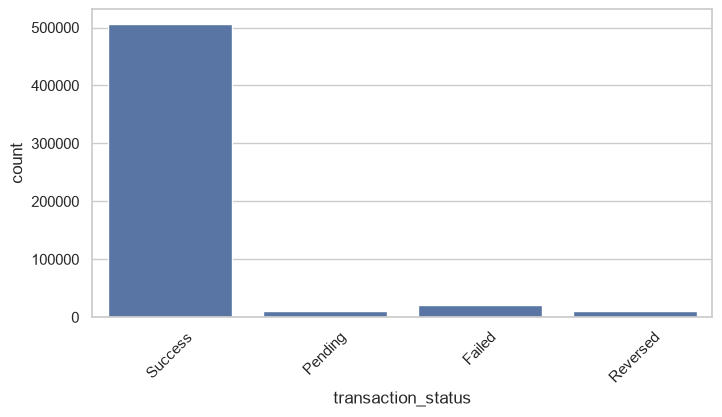

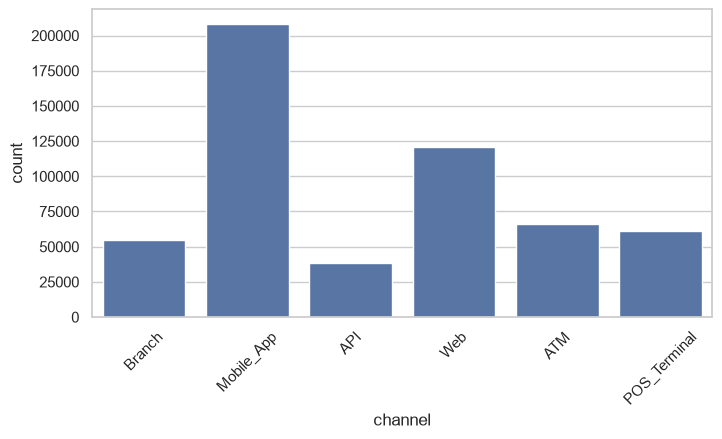

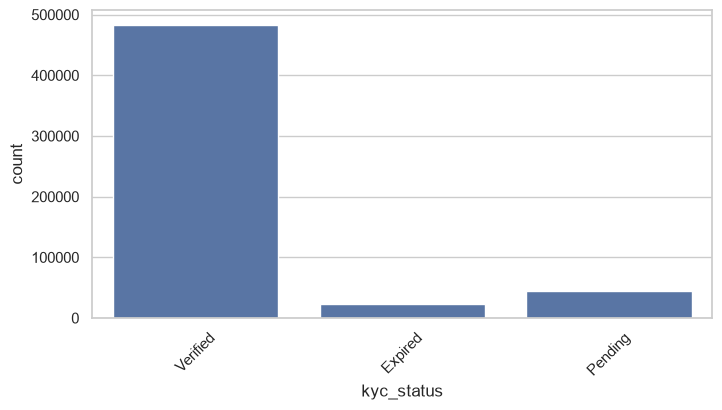

In [23]:
for col in cat_cols:

    if df[col].nunique() <= 20:

        plt.figure(figsize=(8,4))

        sns.countplot(data=df, x=col)

        plt.xticks(rotation=45)

        plt.show()

## Numerical vs Target (Fraud)

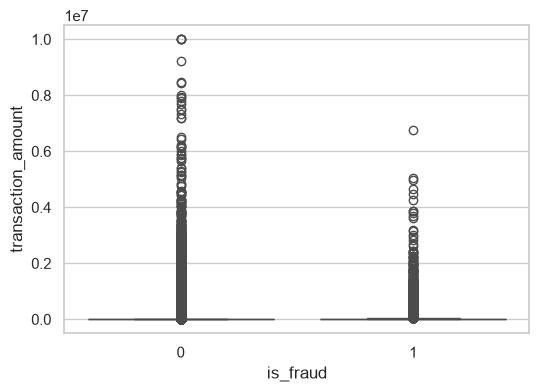

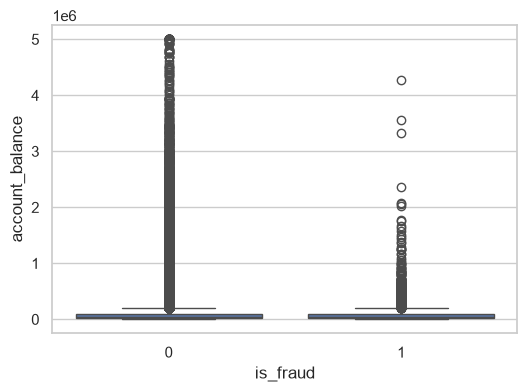

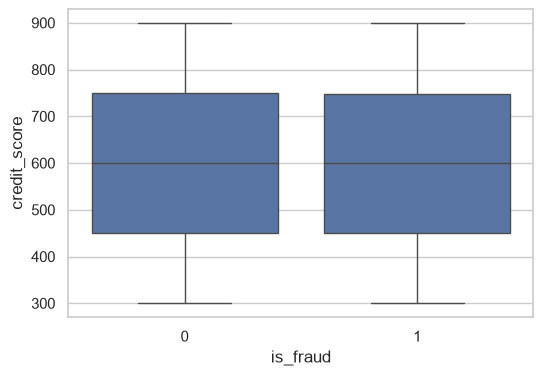

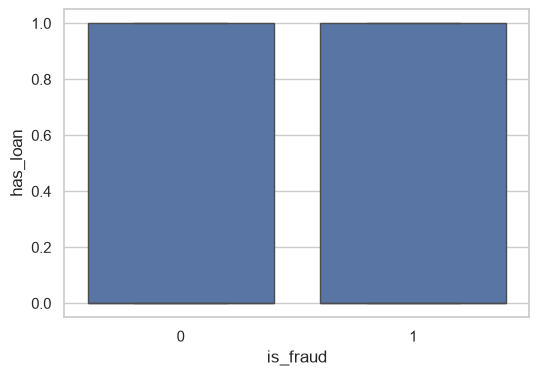

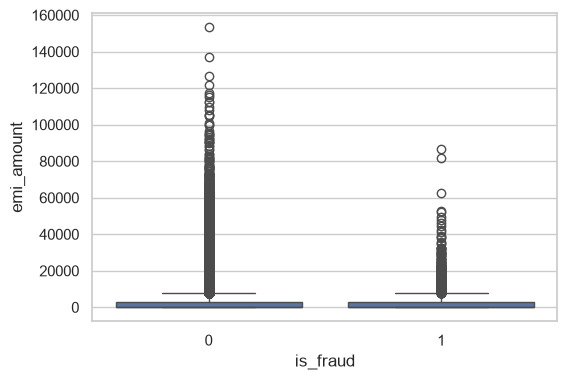

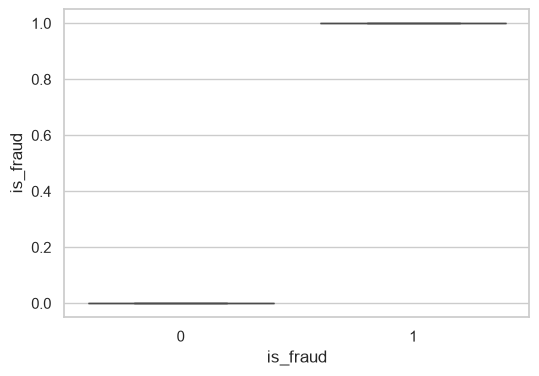

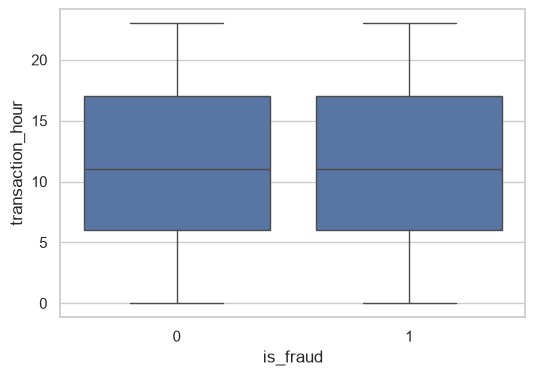

In [24]:
for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        data=df,
        x="is_fraud",
        y=col
    )

    plt.show()

## Categorical vs Target (Fraud)

In [25]:
sample_df = df.sample(50000, random_state=42)

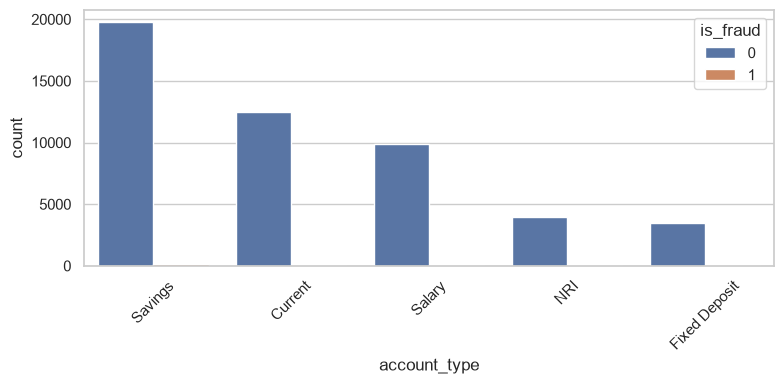

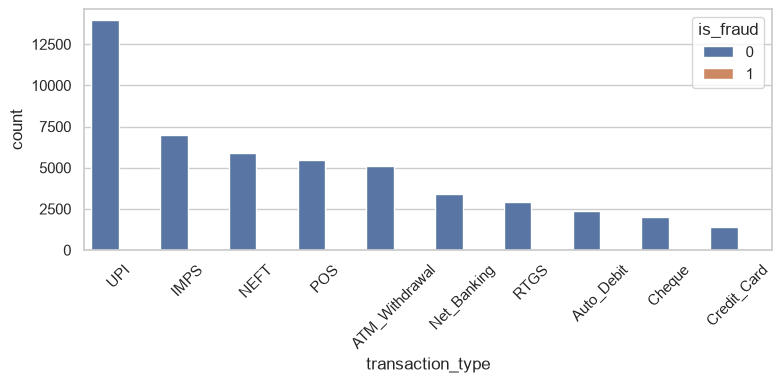

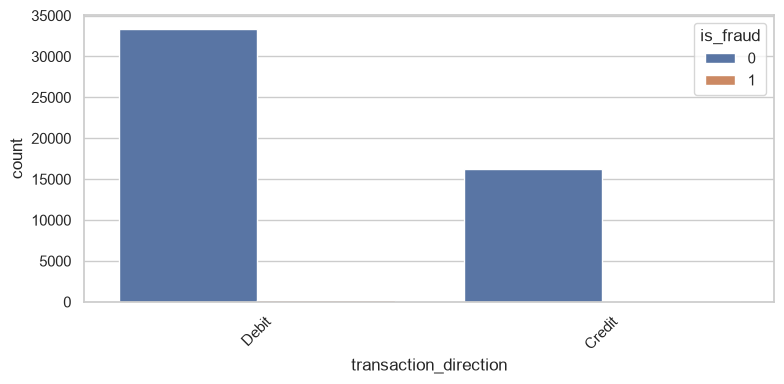

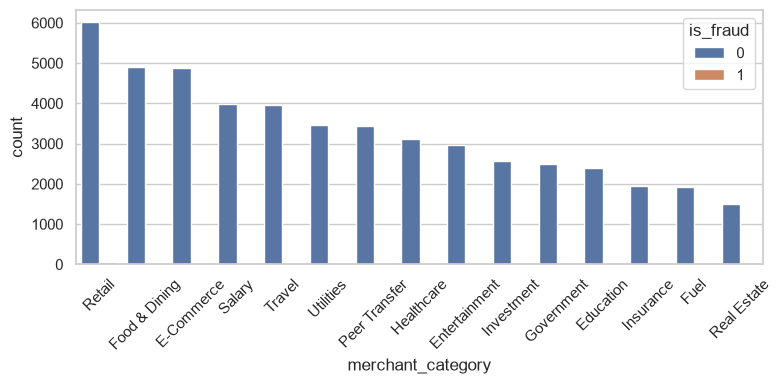

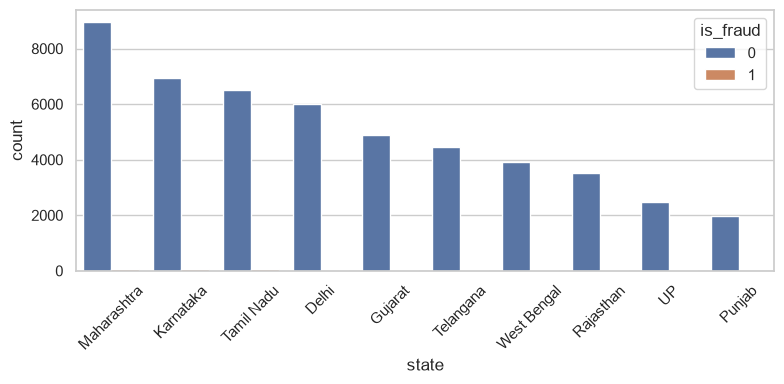

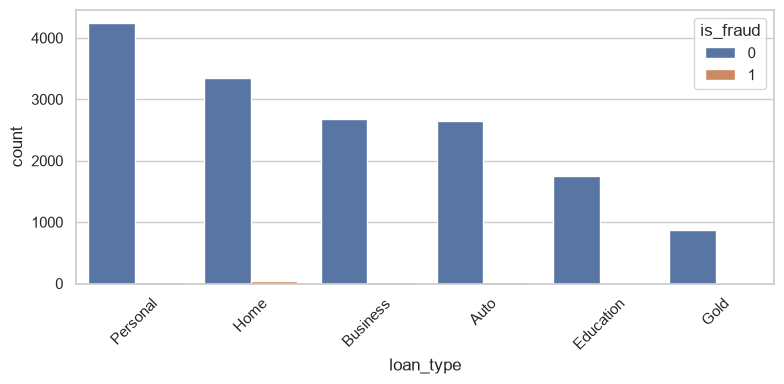

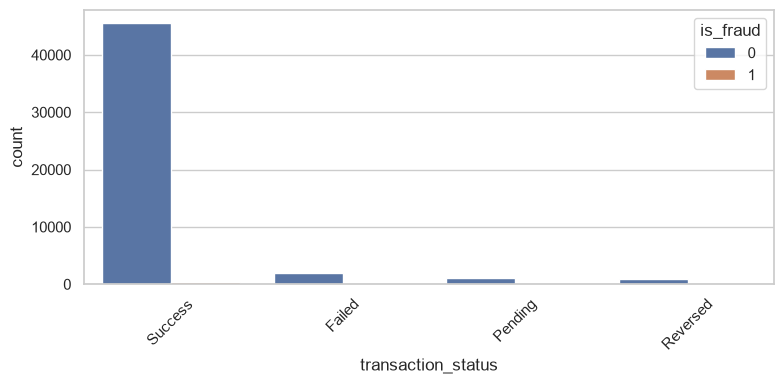

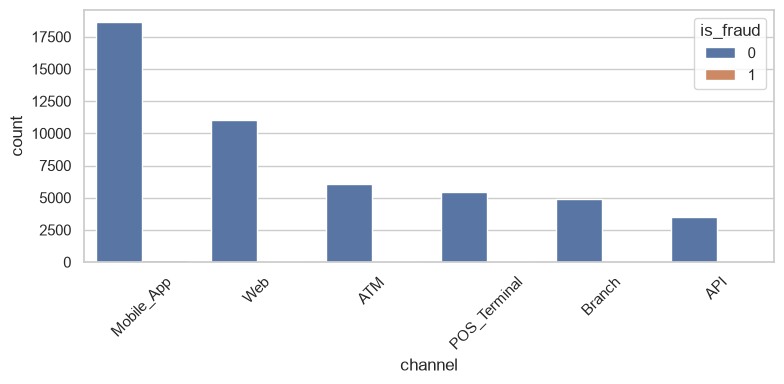

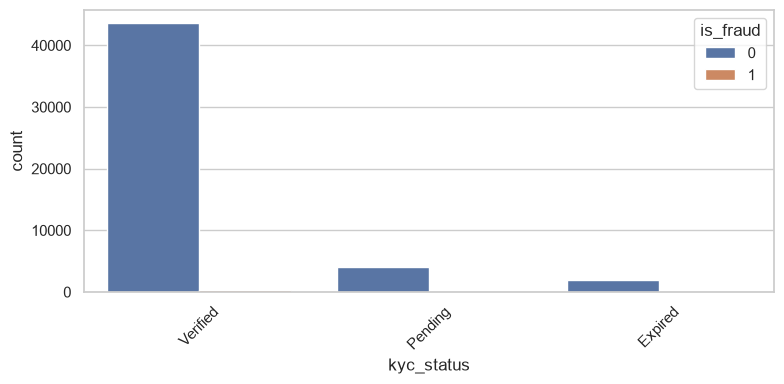

In [26]:
for col in cat_cols:

    if sample_df[col].nunique() <= 15:

        plt.figure(figsize=(8, 4))

        sns.countplot(
            data=sample_df,
            x=col,
            hue="is_fraud",
            order=sample_df[col].value_counts().index
        )

        plt.xticks(rotation=45)

        plt.tight_layout()

        plt.show()

## Correlation Heatmap

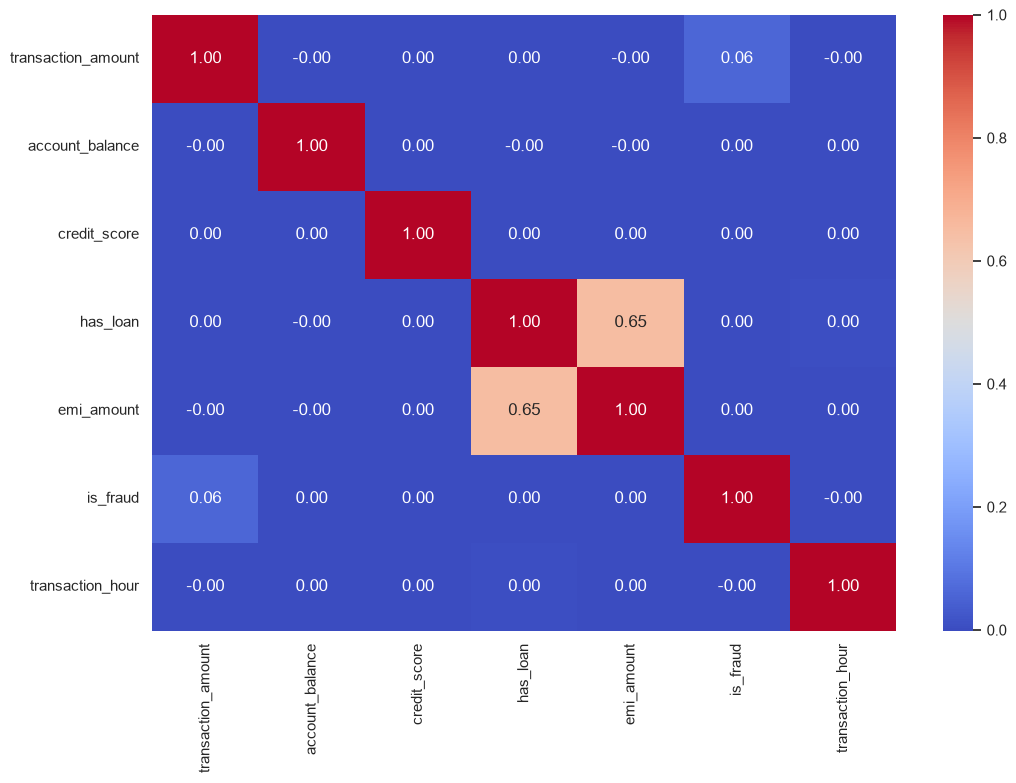

In [27]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

## Pairplot

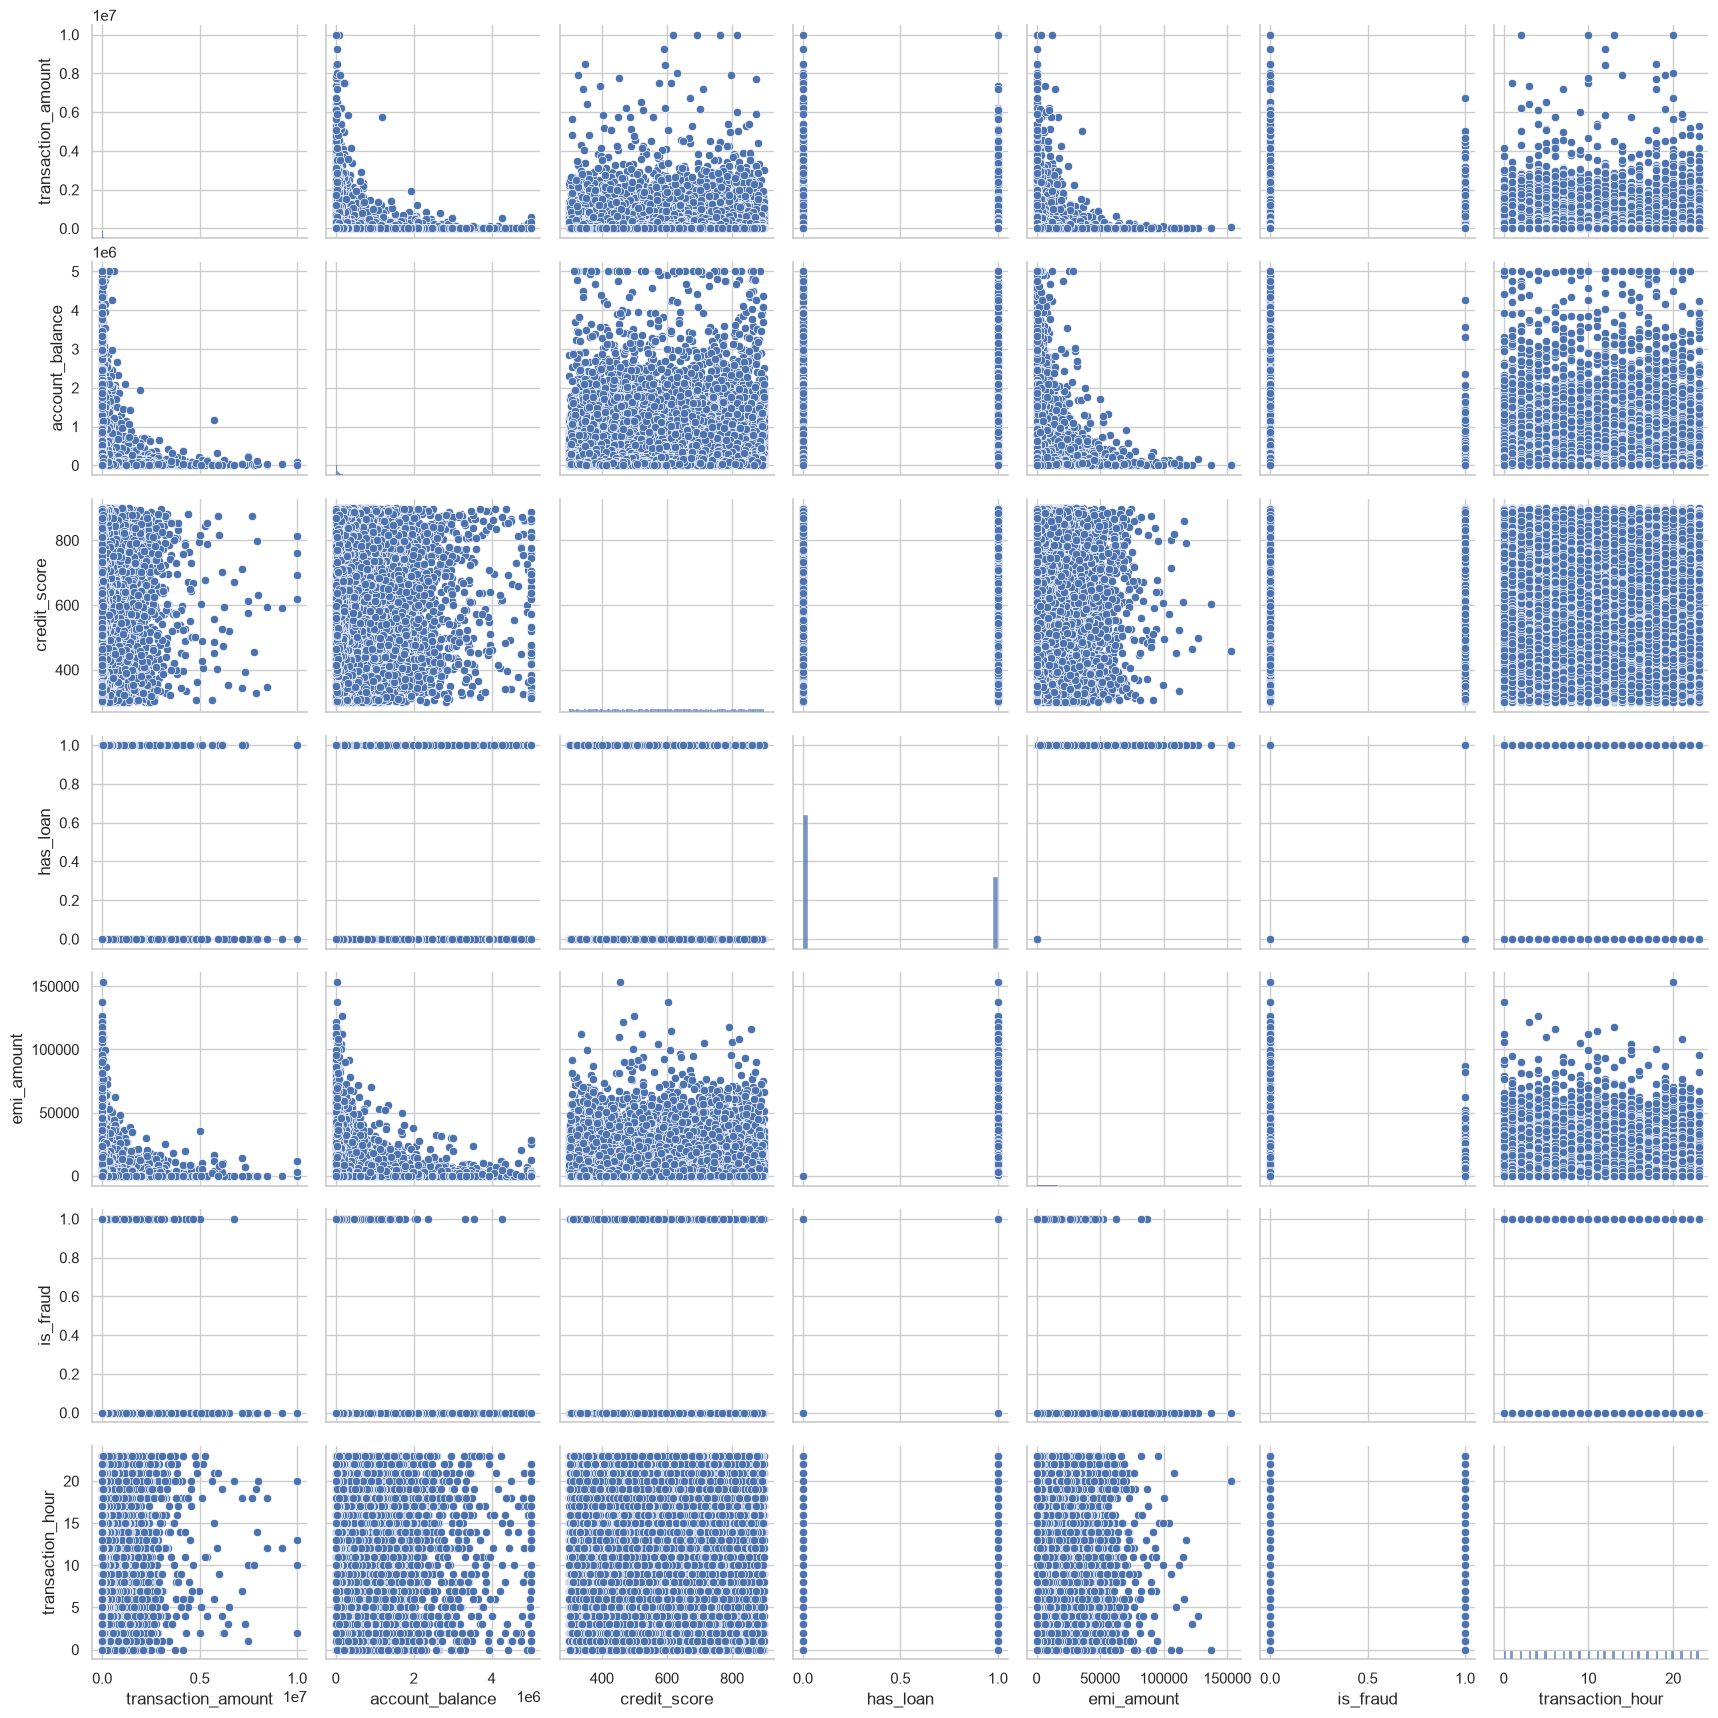

In [28]:
sns.pairplot(
    df[num_cols]
)

## Transaction Amount Analysis

<Axes: xlabel='transaction_amount', ylabel='Count'>

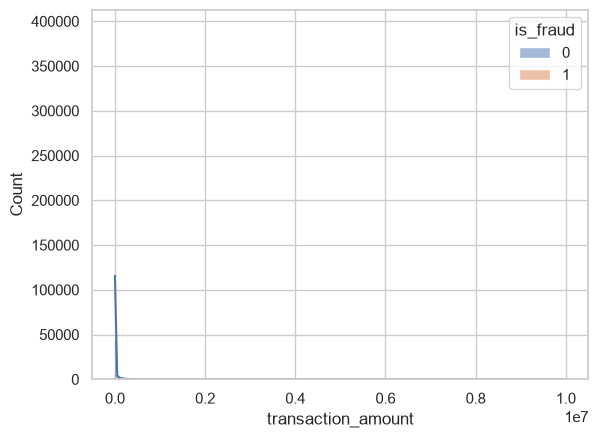

In [29]:
sns.histplot(
    data=df,
    x="transaction_amount",
    hue="is_fraud",
    kde=True
)